# 2 · BG/NBD + Gamma-Gamma, paradoja de supervivencia y evaluación en prueba

En este notebook:
1. Analizamos los parámetros estimados por máxima verosimilitud de **BG/NBD** y **Gamma-Gamma**.
2. Mostramos la diferencia entre **$P(\text{vivo en } T)$** y **$P(Y(t) \ge 1)$** (probabilidad de al menos una compra en los próximos 6 meses), la **paradoja del comprador frecuente en silencio** y la **contracción bayesiana (*shrinkage*)**.
3. Comparamos **BG/NBD + Gamma-Gamma** con heurísticas y con **LightGBM**, con **intervalos de confianza bootstrap** para saber si las diferencias son reales, y revisamos qué ventana de entrenamiento es justa para LightGBM.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ))

from clv import config, datos, evaluacion, predecir, segmentacion
from clv.graficos import estilo, num, AZUL, NARANJA, VERDE, AMARILLO, GRIS
estilo()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

## 2.1 · Parámetros estimados por máxima verosimilitud

In [2]:
meta = predecir.cargar_metadata()
pb, pg = meta["parametros_bgnbd"], meta["parametros_gamma_gamma"]
display(pd.DataFrame([pb]).T.rename(columns={0: "BG/NBD"}))
display(pd.DataFrame([pg]).T.rename(columns={0: "Gamma-Gamma"}))
print(f"Compras esperadas por año de un cliente activo promedio: {pb['tasa_media_compra_semanal'] * 52:.1f}")
print(f"Probabilidad media de abandono tras cada compra: {pb['prob_media_abandono_post_compra'] * 100:.2f} %")

,BG/NBD
r,0.683
alpha_semanas,9.481
a,0.152
b,3.306
log_verosimilitud,"-58,257.110"
tasa_media_compra_semanal,0.072
prob_media_abandono_post_compra,0.044


,Gamma-Gamma
p,2.300
q,3.838
gamma,484.870
ticket_medio_poblacional_gbp,392.810
log_verosimilitud,"-22,486.400"


Compras esperadas por año de un cliente activo promedio: 3.7
Probabilidad media de abandono tras cada compra: 4.39 %


## 2.2 · La paradoja del comprador frecuente en silencio

semanas sin comprar,4,13,26,39
x,,,,
1,95.3%,94.3%,92.3%,89.0%
2,96.2%,94.9%,91.7%,85.3%
6,97.6%,94.9%,83.8%,51.4%
12,98.1%,92.5%,51.8%,5.0%
24,98.2%,76.6%,2.8%,0.0%


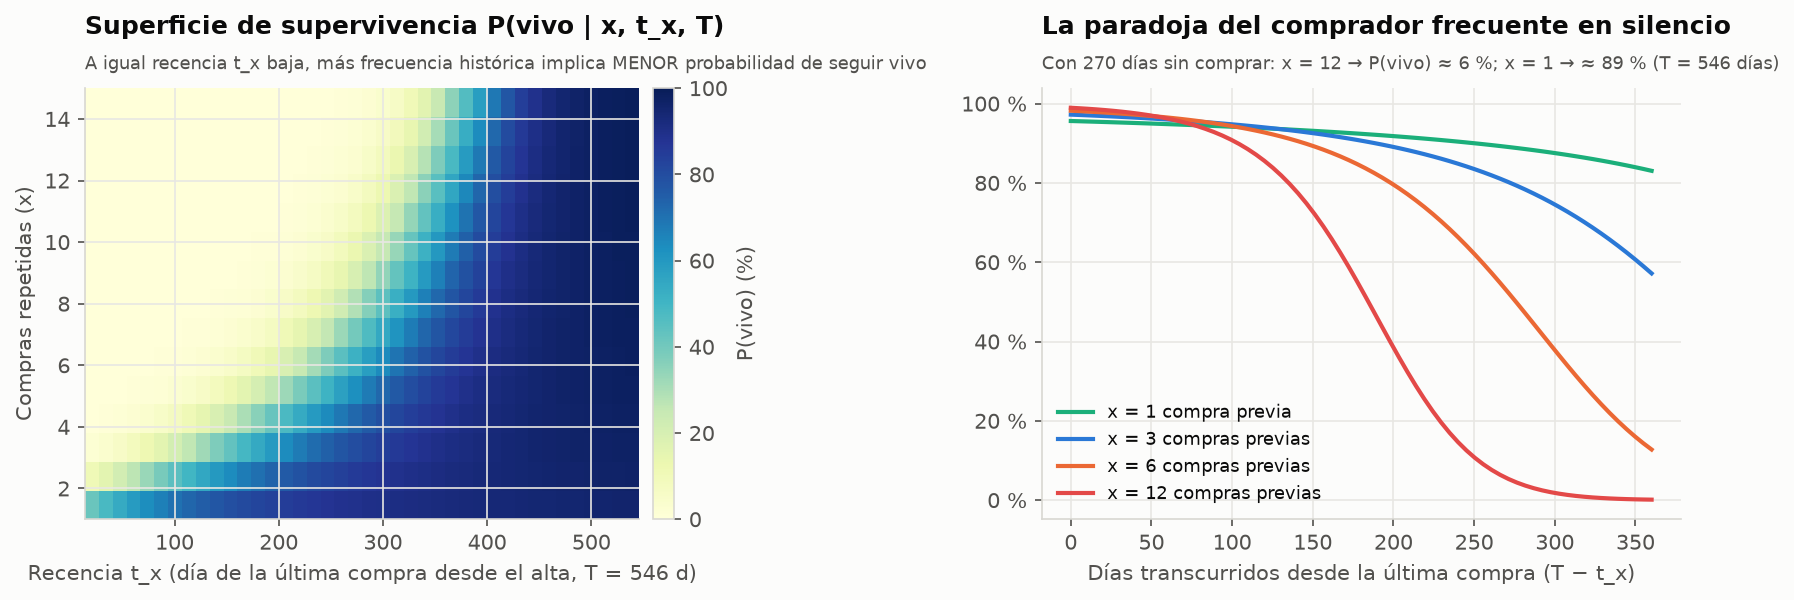

In [3]:
art = predecir.cargar_artefacto()
bg, gg = art["bgnbd"], art["gg"]
T = 78.0  # semanas de antigüedad
filas = []
for x in [1, 2, 6, 12, 24]:
    for inact in [4, 13, 26, 39]:
        t_x = T - inact
        filas.append({"x": x, "semanas sin comprar": inact,
                      "P(vivo)": float(bg.probabilidad_vivo(np.array([x]), np.array([t_x]), np.array([T]))[0]),
                      "P(recompra 6 m)": float(bg.probabilidad_recompra(config.HORIZONTE_SEMANAS, np.array([x]), np.array([t_x]), np.array([T]))[0])})
paradoja = pd.DataFrame(filas)
display(paradoja.pivot(index="x", columns="semanas sin comprar", values="P(vivo)").style.format("{:.1%}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1))
display(Image(filename=str(config.FIGURAS / "04_probabilidad_vivo_matriz.png")))

Con 26 semanas sin comprar, quien había comprado 24 veces está casi seguro de haberse ido, mientras que quien compró una vez sigue probablemente «vivo»: su silencio es compatible con su ritmo lento. Una tabla RFM que premia la frecuencia diría lo contrario.

## 2.3 · Ajuste de frecuencias y calibración por deciles

,frecuencia_tramo,n_clientes,compras_pred_media,compras_real_media,prob_recompra_media,tasa_recompra_real
0,0,1608,0.504,0.450,0.294,0.266
1,1,883,0.770,0.745,0.415,0.408
2,2,563,1.095,1.094,0.532,0.570
3,3,410,1.308,1.246,0.604,0.605
4,4,313,1.638,1.732,0.680,0.693
5,5,189,1.879,1.746,0.726,0.741
6,6,187,2.099,1.979,0.755,0.775
7,7,124,2.528,2.282,0.817,0.839
8,8,112,3.035,3.161,0.864,0.929
9,9,88,3.027,3.023,0.865,0.909


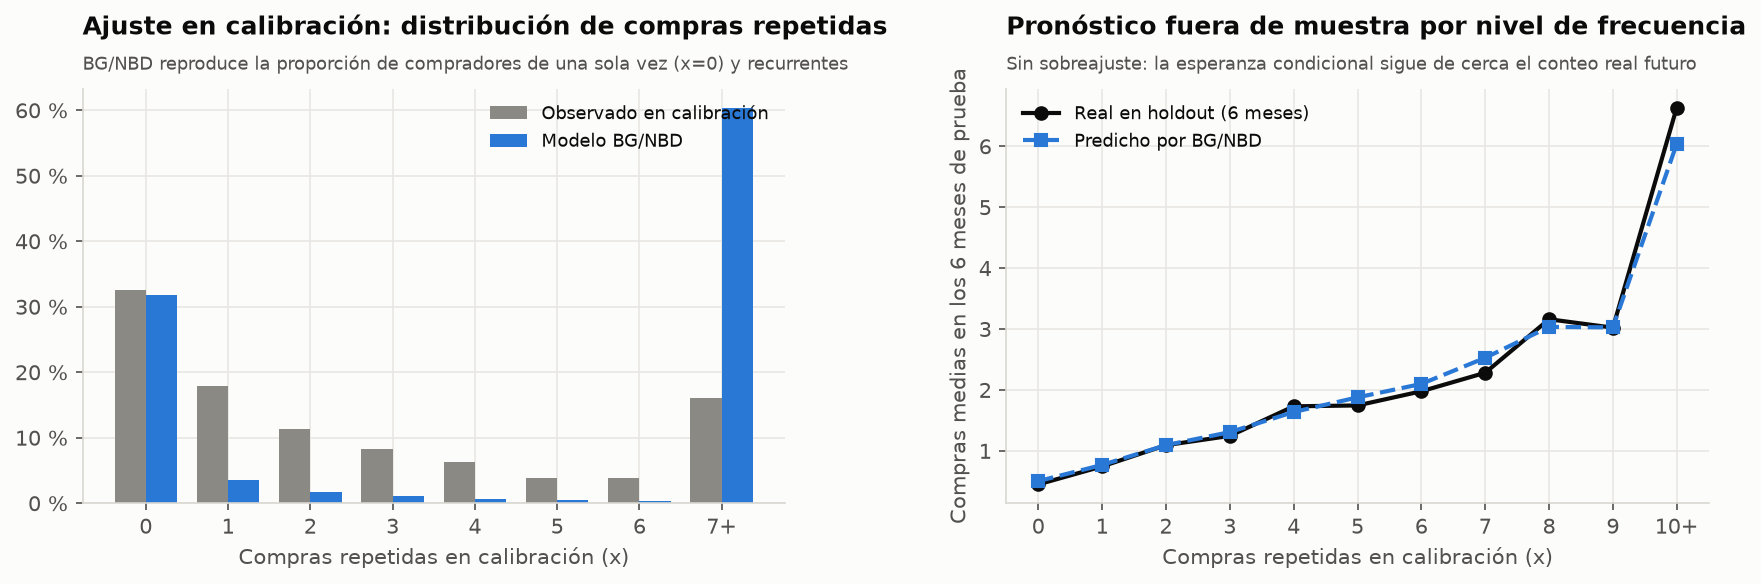

In [4]:
cal_frec = pd.read_csv(config.REPORTES / "calibracion_frecuencia.csv")
display(cal_frec)
display(Image(filename=str(config.FIGURAS / "03_ajuste_bgnbd_frecuencia.png")))

In [5]:
deciles = pd.read_csv(config.REPORTES / "calibracion_deciles.csv")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.plot([0, 1], [0, 1], color=GRIS, linestyle=":")
a1.plot(deciles["prob_recompra_media"], deciles["tasa_recompra_real"], marker="o", color=AZUL)
a1.set_xlabel("P(recompra en 6 m) media predicha"); a1.set_ylabel("Tasa real de recompra"); a1.set_title("Calibración de la recompra por decil")
a2.bar(deciles["decil"] - 0.2, deciles["compras_pred_media"], width=0.4, color=AZUL, label="Predicho")
a2.bar(deciles["decil"] + 0.2, deciles["compras_real_media"], width=0.4, color=NARANJA, label="Real")
a2.set_xlabel("Decil de compras esperadas"); a2.set_ylabel("Compras medias en 6 m"); a2.set_title("Compras predichas vs. reales"); a2.legend()
plt.tight_layout(); plt.show()
deciles[["decil", "prob_recompra_media", "tasa_recompra_real", "compras_pred_media", "compras_real_media", "ingreso_pred_medio", "ingreso_real_medio"]]

,decil,prob_recompra_media,tasa_recompra_real,compras_pred_media,compras_real_media,ingreso_pred_medio,ingreso_real_medio
0,1,0.174,0.133,0.227,0.188,85.339,64.180
1,2,0.245,0.223,0.348,0.289,132.313,117.421
2,3,0.299,0.310,0.449,0.474,167.710,176.119
3,4,0.372,0.329,0.600,0.471,220.695,186.564
4,5,0.445,0.464,0.790,0.777,295.068,274.497
5,6,0.530,0.540,1.023,0.986,370.249,384.747
6,7,0.621,0.626,1.337,1.358,522.609,583.280
7,8,0.725,0.745,1.773,1.779,676.789,699.124
8,9,0.848,0.879,2.627,2.567,"1,050.032","1,130.497"
9,10,0.956,0.954,6.285,6.788,"3,165.677","3,816.026"


La recompra está bien calibrada en todos los deciles. En el decil más alto el modelo subestima el ingreso: son clientes muy frecuentes cuyo ticket se contrae hacia la media (supuesto de Gamma-Gamma solo aproximado) y que además compran más en el pico navideño.

## 2.4 · Contracción bayesiana (*shrinkage*) del ticket

x =  1: peso del historial propio  44.8 % → ticket esperado para m_x = 1.200 GBP: 754 GBP
x =  3: peso del historial propio  70.8 % → ticket esperado para m_x = 1.200 GBP: 965 GBP
x = 10: peso del historial propio  89.0 % → ticket esperado para m_x = 1.200 GBP: 1,111 GBP


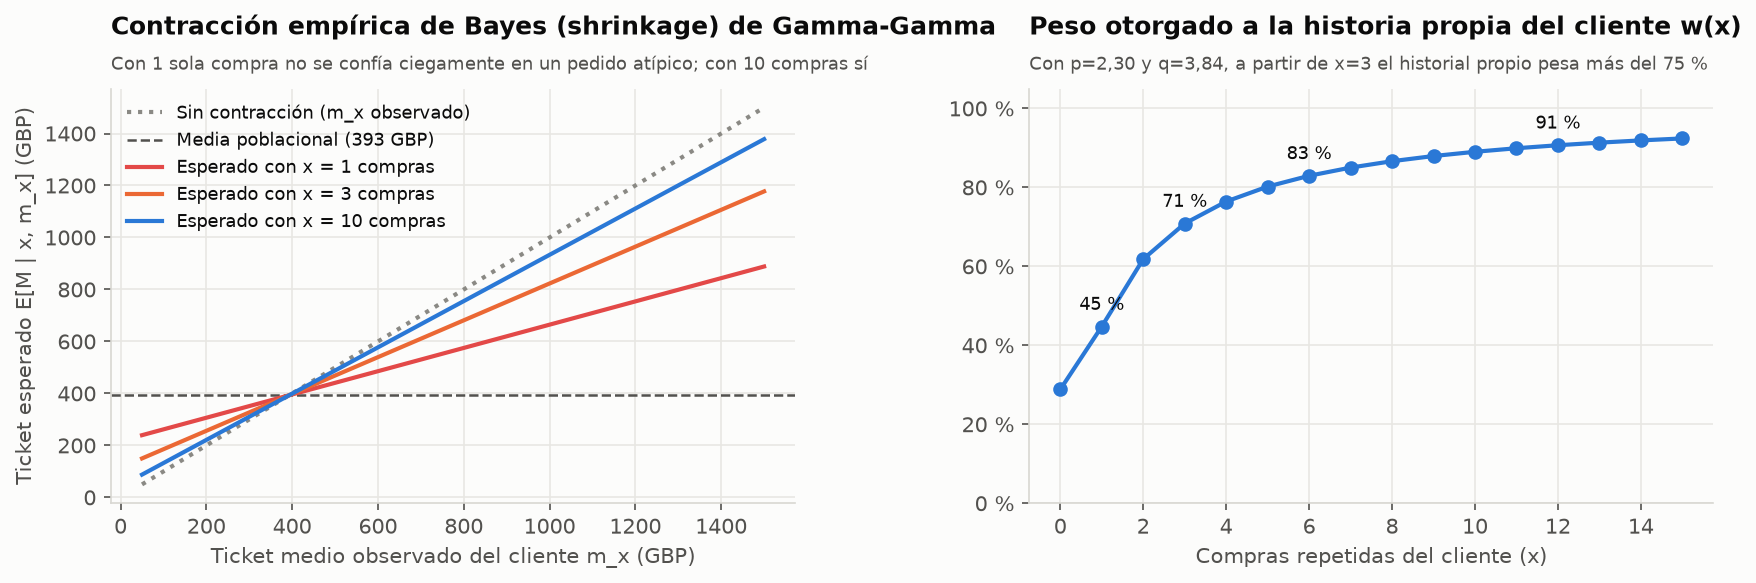

In [6]:
for x in [1, 3, 10]:
    w = float(gg.peso_credibilidad(np.array([x]))[0])
    t = float(gg.ticket_esperado(np.array([x]), np.array([1200.0]))[0])
    print(f"x = {x:>2}: peso del historial propio {w * 100:5.1f} % → ticket esperado para m_x = 1.200 GBP: {t:,.0f} GBP")
display(Image(filename=str(config.FIGURAS / "06_shrinkage_gamma_gamma.png")))

## 2.5 · Comparación en los 6 meses de prueba

,modelo,auc_recompra,brier_recompra,mae_compras,rmse_compras,sesgo_compras_pct,spearman_compras,mae_ingreso_gbp,rmse_ingreso_gbp,error_cartera_pct,spearman_ingreso,captura_top10_pct,captura_top20_pct
0,Ritmo histórico (heurística),0.762,0.218,1.064,1.861,-3.208,0.591,481.908,"1,275.454",-12.397,0.608,55.228,70.688
1,Tabla RFM por tramos,0.774,0.201,1.191,2.742,-21.826,0.566,665.030,"2,336.213",-23.803,0.546,50.972,64.608
2,LightGBM supervisado,0.800,0.190,1.097,2.074,-26.930,0.607,526.715,"1,728.074",-40.923,0.603,56.513,71.604
3,BG/NBD + Gamma-Gamma,0.810,0.177,1.045,1.784,-1.395,0.624,485.819,"1,278.606",-10.042,0.636,57.070,72.024


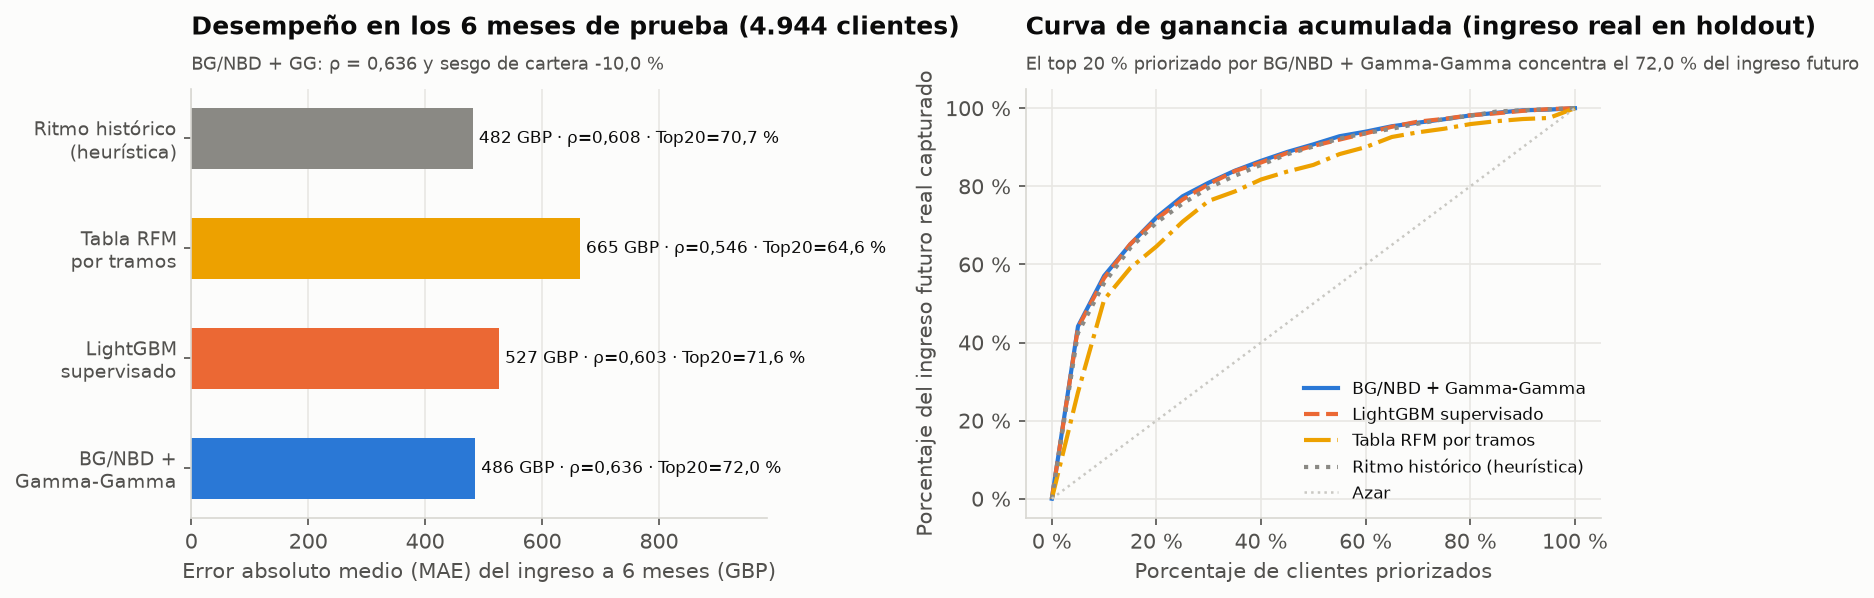

In [7]:
comp = pd.read_csv(config.REPORTES / "comparacion_modelos.csv")
display(comp)
display(Image(filename=str(config.FIGURAS / "07_comparacion_modelos_clv.png")))

### ¿La ventaja sobre LightGBM es real? Bootstrap pareado

Remuestreamos 1.000 veces los 4.944 clientes (los mismos para ambos modelos) y calculamos la diferencia BG/NBD − LightGBM. Si el intervalo del 95 % no contiene el 0, la diferencia es significativa.

In [8]:
boot = pd.read_csv(config.REPORTES / "bootstrap_bgnbd_vs_lightgbm.csv")
display(boot[["metrica", "valor_a", "valor_b", "diferencia_a_menos_b", "ic95_inf", "ic95_sup", "significativa_95"]])
fig, axes = plt.subplots(1, len(boot), figsize=(13, 2.6))
for ax, (_, f) in zip(axes, boot.iterrows()):
    ax.errorbar([0], [f["diferencia_a_menos_b"]], yerr=[[f["diferencia_a_menos_b"] - f["ic95_inf"]], [f["ic95_sup"] - f["diferencia_a_menos_b"]]],
                fmt="o", color=AZUL if f["significativa_95"] else GRIS, capsize=5)
    ax.axhline(0, color=NARANJA, linewidth=1); ax.set_xticks([]); ax.set_title(f["metrica"], fontsize=9)
fig.suptitle("Diferencia BG/NBD + GG − LightGBM con IC 95 % (azul = significativa)", fontsize=10)
plt.tight_layout(); plt.show()

,metrica,valor_a,valor_b,diferencia_a_menos_b,ic95_inf,ic95_sup,significativa_95
0,auc_recompra,0.810,0.800,0.010,0.004,0.017,True
1,brier_recompra,0.177,0.190,-0.012,-0.016,-0.009,True
2,spearman_compras,0.624,0.607,0.018,0.008,0.029,True
3,spearman_ingreso,0.636,0.603,0.033,0.021,0.046,True
4,captura_top20_pct,72.024,71.604,0.420,-0.592,1.157,False


BG/NBD + Gamma-Gamma es mejor que LightGBM en AUC, Brier y correlación de Spearman con diferencias pequeñas pero **significativas** (los intervalos no tocan el 0). En la **captura del top 20 %** la diferencia no es significativa: para elegir a quién priorizar, ambos modelos son equivalentes.

### ¿LightGBM se entrenó con una ventana justa?

Un modelo supervisado necesita etiquetas, así que no puede usar la misma ventana que BG/NBD sin mirar la prueba. La versión principal se entrena con corte en `2010-12-09` y objetivo diciembre–junio. Como prueba de robustez, entrenamos otra con la **misma estación** que la prueba (corte `2010-06-09`, objetivo junio–diciembre de 2010), a costa de tener solo 190 días de historia.

In [9]:
ventanas = pd.read_csv(config.REPORTES / "lightgbm_ventanas.csv")
ventanas[["modelo", "clientes_entrenamiento", "auc_recompra", "brier_recompra", "sesgo_compras_pct", "spearman_ingreso", "error_cartera_pct", "captura_top20_pct"]]

,modelo,clientes_entrenamiento,auc_recompra,brier_recompra,sesgo_compras_pct,spearman_ingreso,error_cartera_pct,captura_top20_pct
0,"LightGBM · ventana previa (corte 2010-12-09, o...",4285,0.800,0.190,-26.930,0.603,-40.923,71.604
1,"LightGBM · misma estación (corte 2010-06-09, o...",2775,0.774,0.258,109.809,0.580,100.451,71.102
2,BG/NBD + Gamma-Gamma,4944,0.810,0.177,-1.395,0.636,-10.042,72.024


La versión de la misma estación corrige el signo del sesgo pero lo invierte con creces (+100 % de ingreso) y empeora el AUC y el Brier: con solo 190 días de historia, las variables de antigüedad y frecuencia no se parecen a las del corte de 2011 (555 días). Ninguna ventana supervisada iguala a BG/NBD, que usa toda la historia hasta el corte sin necesitar etiquetas. Por eso la tabla principal conserva la ventana previa y el README aclara que su −40,9 % de ingreso se debe sobre todo a la estacionalidad.